In [20]:
# @title
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path
from typing import Tuple

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


BASE_FEATURES = ["P_laser", "v_scan", "d_laser", "t_powder"]
DERIVED_FEATURES = ["linear_energy", "peclet_number", "normalized_enthalpy"]

# v3 physical-state representation:
#   W = melt-pool width [um]
#   R = D/W = melt-pool aspect ratio [-]
#   A = melt-pool cross-sectional area [um^2]
TARGETS = ["melt_width", "aspect_ratio", "melt_area"]
RISK = "balling"


def get_features(include_linear_energy: bool = True) -> list[str]:
    """Return model input features.

    Raw process variables are always retained. Linear energy density P/v is
    an additional derived feature; it does not replace P_laser or v_scan.
    """
    return BASE_FEATURES + (DERIVED_FEATURES if include_linear_energy else [])


FEATURES = get_features(True)


def load_316l_csv(path: str | Path) -> pd.DataFrame:
    """Load the supplied 316L single-track CSV and derive v3 geometry state."""
    path = Path(path)
    df = pd.read_csv(path, header=None, skiprows=1)
    if df.shape[1] != 9:
        raise ValueError(f"Expected 9 columns including ID, got {df.shape[1]}")

    df.columns = [
        "id", "P_laser", "v_scan", "d_laser", "t_powder",
        "melt_width", "melt_depth", "melt_area", "balling",
    ]
    df[df.columns] = df[df.columns].apply(pd.to_numeric, errors="raise")
    df["id"] = df["id"].astype(int)
    df["balling"] = df["balling"].astype(np.float32)

    # J/mm: W / (mm/s) = J/mm.
    df["linear_energy"] = df["P_laser"] / df["v_scan"]

    # Conventions: d_laser is treated as the laser spot DIAMETER; v_scan is
    # converted from mm/s to m/s. These conventions match the normalized
    # enthalpy / Peclet definitions used by the scaling-law literature.
    #
    # Pe = v*d/alpha
    # H* = eta*P / (h_s * sqrt(alpha*d^3*v))
    # where h_s = rho*cp*(Tm-T0) is the sensible enthalpy density needed
    # to heat the material from T0 to the melting temperature.
    rho_316l = 7800.0              # kg/m^3
    cp_316l = 460.0                # J/(kg K)
    alpha_316l = 5.0e-6            # m^2/s, representative 316L value
    Tm_316l = 1678.0               # K
    T0_316l = 293.15               # K
    absorptivity_316l = 0.34
    h_s_vol = rho_316l * cp_316l * (Tm_316l - T0_316l)

    v_mps = np.maximum(df["v_scan"].to_numpy(dtype=float) / 1000.0, 1e-12)
    diameter_m = np.maximum(df["d_laser"].to_numpy(dtype=float) / 1000.0, 1e-12)
    power_w = np.maximum(df["P_laser"].to_numpy(dtype=float), 1e-12)
    df["peclet_number"] = v_mps * diameter_m / alpha_316l
    df["normalized_enthalpy"] = (
        absorptivity_316l * power_w
        / (h_s_vol * np.sqrt(alpha_316l * diameter_m**3 * v_mps))
    )

    # v3 physical representation.
    # Aspect ratio is intentionally computed from the measured geometry rather
    # than predicted independently:
    #     R = D / W
    # It will later be used to reconstruct physical depth as D = W * R.
    width = df["melt_width"].clip(lower=1e-6)
    df["aspect_ratio"] = df["melt_depth"] / width

    if not np.isfinite(df["aspect_ratio"]).all():
        raise ValueError("Non-finite aspect_ratio found in melt-pool data")

    return df


@dataclass
class DataScalers:
    x: StandardScaler
    y: StandardScaler
    features: list[str]
    targets: list[str]



def make_iid_split(
    df: pd.DataFrame,
    seed: int = 42,
    train_ratio: float = 0.70,
    val_ratio: float = 0.15,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    """Initial IID split. A process-space split can be added as a separate experiment."""
    train, temp = train_test_split(df, test_size=1.0 - train_ratio, random_state=seed)
    relative_val = val_ratio / (1.0 - train_ratio)
    val, test = train_test_split(temp, test_size=1.0 - relative_val, random_state=seed)
    return train.reset_index(drop=True), val.reset_index(drop=True), test.reset_index(drop=True)



def fit_scalers(train_df: pd.DataFrame, include_linear_energy: bool = True) -> DataScalers:
    features = get_features(include_linear_energy)
    x = StandardScaler().fit(train_df[features])
    y = StandardScaler().fit(train_df[TARGETS])
    return DataScalers(x=x, y=y, features=features, targets=TARGETS.copy())


class MeltPoolDataset(Dataset):
    def __init__(self, df: pd.DataFrame, scalers: DataScalers):
        self.df = df.reset_index(drop=True)
        self.x = scalers.x.transform(self.df[scalers.features]).astype(np.float32)
        self.y = scalers.y.transform(self.df[scalers.targets]).astype(np.float32)
        self.balling = self.df[RISK].to_numpy(dtype=np.float32)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        return {
            "x": torch.from_numpy(self.x[idx]),
            "y": torch.from_numpy(self.y[idx]),
            "balling": torch.tensor(self.balling[idx]),
            "id": int(self.df.iloc[idx]["id"]),
        }


In [21]:
# @title
from __future__ import annotations

import torch
from torch import nn


class DeepSupervisionLoss(nn.Module): # param 가중치 조절
    """
    L = L_data + alpha * L_physics
    """

    def __init__(self, gamma: float = 0.8, state_weights=(1.0, 1.0, 1.0)):
        super().__init__()
        weights = torch.as_tensor(state_weights, dtype=torch.float32)
        if weights.ndim != 1 or weights.numel() != 3:
            raise ValueError("state_weights must contain exactly 3 values: W, R, A")
        if torch.any(weights <= 0):
            raise ValueError("state_weights must be positive")
        self.gamma = gamma
        self.register_buffer("state_weights", weights)

    def forward(self, predictions, target):
        if target.size(-1) != self.state_weights.numel():
            raise ValueError(
                f"Expected target dimension {self.state_weights.numel()}, got {target.size(-1)}"
            )

        total = target.new_tensor(0.0)
        weight_sum = 0.0
        for k, pred in enumerate(predictions):
            loop_weight = self.gamma ** (len(predictions) - 1 - k)
            per_state = (pred - target).pow(2).mean(dim=0)
            state_loss = (per_state * self.state_weights.to(pred)).sum() / self.state_weights.sum()
            total = total + loop_weight * state_loss
            weight_sum += loop_weight
        return total / weight_sum

class PhysicsConsistencyLoss(nn.Module):
    """Mean squared physics residual"""

    def forward(self, feedbacks, confidences=None):
        if not feedbacks:
            return torch.tensor(0.0)

        terms = []
        for i, feedback in enumerate(feedbacks):
            if confidences is not None and confidences[i] is not None:
                mask = confidences[i]
                denom = mask.sum().clamp_min(1.0)
                terms.append((feedback.pow(2) * mask).sum() / denom)
            else:
                terms.append(feedback.pow(2).mean())
        return torch.stack(terms).mean()


In [22]:
# @title
from __future__ import annotations

from abc import ABC, abstractmethod
from dataclasses import dataclass

import math
import torch


@dataclass
class PhysicsFeedback:
    residual: torch.Tensor
    confidence: torch.Tensor | None = None


class PhysicsEvaluator(ABC):
    @abstractmethod
    def evaluate(self, process_x: torch.Tensor, predicted_state: torch.Tensor) -> PhysicsFeedback:
        raise NotImplementedError


class ZeroPhysicsEvaluator(PhysicsEvaluator):
    """아키텍처 검증 전용"""

    def evaluate(self, process_x, predicted_state):
        return PhysicsFeedback(residual=torch.zeros_like(predicted_state))


class RosenthalPhysicsEvaluator(PhysicsEvaluator): #Rosenthal의 열역학 모델
    """
    물리 모델:
        W = sqrt( 8/(pi*e) * eta*P / (rho*Cp*v*DeltaT) )
        R = D/W
        A = pi/4 * W * D

    평가:
        L=λW*LW​+λD​*LD​+λA*​LA​
    """

    def __init__(
        self,
        x_mean,
        x_scale,
        y_mean,
        y_scale,
        absorptivity: float = 0.34,
        density: float = 7800.0,
        heat_capacity: float = 460.0,
        thermal_diffusivity: float = 5.0e-6,
        melting_temperature: float = 1678.0,
        preheat_temperature: float = 293.15,
        scaling_k: float = 0.60,
        residual_clip: float = 5.0,
    ):
        self.x_mean = torch.as_tensor(x_mean, dtype=torch.float32)
        self.x_scale = torch.as_tensor(x_scale, dtype=torch.float32)
        self.y_mean = torch.as_tensor(y_mean, dtype=torch.float32)
        self.y_scale = torch.as_tensor(y_scale, dtype=torch.float32)
        self.absorptivity = absorptivity
        self.density = density
        self.heat_capacity = heat_capacity
        self.thermal_diffusivity = thermal_diffusivity
        self.melting_temperature = melting_temperature
        self.preheat_temperature = preheat_temperature
        self.scaling_k = scaling_k
        self.residual_clip = residual_clip

    def _physical_x(self, x: torch.Tensor) -> torch.Tensor:
        mean = self.x_mean.to(device=x.device, dtype=x.dtype)
        scale = self.x_scale.to(device=x.device, dtype=x.dtype)
        return x * scale + mean

    def _physical_y(self, y: torch.Tensor) -> torch.Tensor:
        mean = self.y_mean.to(device=y.device, dtype=y.dtype)
        scale = self.y_scale.to(device=y.device, dtype=y.dtype)
        return y * scale + mean

    def thermal_features(self, process_x: torch.Tensor):
        x = self._physical_x(process_x)
        P = x[:, 0].clamp_min(1e-6)
        v = (x[:, 1] / 1000.0).clamp_min(1e-9)
        diameter = (x[:, 2] / 1000.0).clamp_min(1e-9)

        Pe = v * diameter / self.thermal_diffusivity
        hs_vol = self.density * self.heat_capacity * (
            self.melting_temperature - self.preheat_temperature
        )
        h_star = self.absorptivity * P / (
            hs_vol * torch.sqrt(self.thermal_diffusivity * diameter**3 * v)
        )
        return P, v, diameter, Pe, h_star

    def rosenthal_width(self, process_x: torch.Tensor) -> torch.Tensor:
        """P 및 v 원시 입력을 사용하여 로젠탈 폭을 마이크로미터 단위로 반환합니다."""
        P, v, _, _, _ = self.thermal_features(process_x)
        delta_T = self.melting_temperature - self.preheat_temperature
        width_m = torch.sqrt(
            (8.0 / (math.pi * math.e))
            * self.absorptivity * P
            / (self.density * self.heat_capacity * v * delta_T)
        )
        return width_m * 1e6

    def scaling_depth(self, process_x: torch.Tensor) -> torch.Tensor:
        """마이크로미터 단위의 soft 스케일링 depth 추정치를 반환합니다.

        Using beta = H*/pi and L_th = Pe^(-1/2),
            D / d_laser ~= K * beta * L_th.

        분석용이지 Target은 아님에 주의.
        """
        _, _, diameter, Pe, h_star = self.thermal_features(process_x)
        beta = h_star / math.pi
        normalized_depth = self.scaling_k * beta / torch.sqrt(Pe.clamp_min(1e-12))
        return diameter * normalized_depth * 1e6

    def evaluate(self, process_x: torch.Tensor, predicted_state: torch.Tensor) -> PhysicsFeedback:
        pred = self._physical_y(predicted_state)
        pred_w, pred_r, pred_a = pred.unbind(dim=-1)
        eps = torch.tensor(1e-6, device=pred.device, dtype=pred.dtype)

        ros_w = self.rosenthal_width(process_x)
        phys_d = self.scaling_depth(process_x)
        phys_r = phys_d / pred_w.clamp_min(eps)
        phys_r = phys_r.clamp(min=0.15, max=2.5)
        pred_d = pred_w * pred_r

        r_width = (pred_w - ros_w) / (ros_w.abs() + eps)

        # 로그-비 잔차는 큰 종횡비 값이 피드백을 지배하는 것을 방지하고
        # 기하학적 오차를 대칭적으로 처리합니다.
        raw_r_residual = (
            torch.log(pred_r.clamp_min(1e-4))
            - torch.log(phys_r.clamp_min(1e-4))
        )

        # 분석 법칙이 모델 학습을 압도하지 않도록 기하 신뢰도를 조절합니다.
        R_PHYSICS_CONFIDENCE = 0.25
        r_aspect = R_PHYSICS_CONFIDENCE * raw_r_residual

        # 타원 면적 일관성 식: A ≈ pi/4 * W^2 * R (W * D)
        ellipse_area = math.pi / 4.0 * pred_w.clamp_min(eps) * pred_d.clamp_min(eps)
        r_area = (pred_a - ellipse_area) / (ellipse_area.abs() + eps)

        residual = torch.stack([r_width, r_aspect, r_area], dim=-1)
        residual = torch.clamp(residual, -self.residual_clip, self.residual_clip)

        # Balling 또는 Extreme R 상태(예: R < 0.2 또는 R > 2.0)에서는 단순 타원 가정의 신뢰도를 감쇄합니다.
        regime_penalty = torch.ones_like(pred_r)
        extreme_mask = (pred_r < 0.2) | (pred_r > 2.0)
        regime_penalty[extreme_mask] = 0.1

        # R_PHYSICS_CONFIDENCE 및 면적 일관성 신뢰도에 물리적 영역 패널티를 곱해줍니다.
        confidence_r_tensor = torch.full_like(r_width, R_PHYSICS_CONFIDENCE) * regime_penalty
        confidence_area = torch.ones_like(r_area) * regime_penalty

        confidence = torch.stack(
            [torch.ones_like(r_width), confidence_r_tensor, confidence_area], dim=-1
        )
        return PhysicsFeedback(residual=residual, confidence=confidence)


class DeltaFeedbackEvaluator(PhysicsEvaluator):
    """Debug 전용"""

    def __init__(self, state_dim: int = 3):
        self.state_dim = state_dim
        self.previous = None

    def reset(self):
        self.previous = None

    def evaluate(self, process_x, predicted_state):
        if self.previous is None:
            residual = torch.zeros_like(predicted_state)
        else:
            residual = predicted_state - self.previous
        self.previous = predicted_state.detach()
        return PhysicsFeedback(residual=residual)


In [23]:
# @title
class FluidThermalPhysicsEvaluator(RosenthalPhysicsEvaluator):
    """
    Thermal + Fluid Physics Evaluator.
    Computes Marangoni (Ma), Reynolds (Re), Weber (We), and Capillary (Ca) numbers
    alongside Normalized Enthalpy and Rosenthal Width discrepancies.

    Feedback vector structure to LoopedTransformer:
        [width_discrepancy, aspect_ratio_residual, area_discrepancy, Ma_normalized, Re_normalized, We_normalized, Ca_normalized]
    """
    def __init__(
        self,
        x_mean,
        x_scale,
        y_mean,
        y_scale,
        absorptivity: float = 0.34,
        density: float = 7800.0,              # kg/m^3
        heat_capacity: float = 460.0,          # J/(kg K)
        thermal_diffusivity: float = 5.0e-6,   # m^2/s
        melting_temperature: float = 1678.0,   # K
        preheat_temperature: float = 293.15,   # K
        viscosity: float = 6.0e-3,             # Pa s (liquid metal viscosity)
        surface_tension: float = 1.2,          # N/m
        dsigma_dT: float = -2.6e-4,            # N/(m K) (Marangoni coefficient)
        scaling_k: float = 0.60,
        residual_clip: float = 5.0
    ):
        super().__init__(
            x_mean, x_scale, y_mean, y_scale,
            absorptivity, density, heat_capacity,
            thermal_diffusivity, melting_temperature, preheat_temperature,
            scaling_k, residual_clip
        )
        self.viscosity = viscosity
        self.surface_tension = surface_tension
        self.dsigma_dT = abs(dsigma_dT)

    def evaluate(self, process_x: torch.Tensor, predicted_state: torch.Tensor) -> PhysicsFeedback:
        # 1. Thermal features and physical values reconstruction
        pred = self._physical_y(predicted_state)
        pred_w, pred_r, pred_a = pred.unbind(dim=-1)
        eps = torch.tensor(1e-6, device=pred.device, dtype=pred.dtype)

        P, v, diameter, Pe, h_star = self.thermal_features(process_x)

        # 2. Temperature rise estimation (Delta T)
        # Reference DeltaT = (Tm - T0) scaled with normalized enthalpy to account for power input
        delta_T_ref = self.melting_temperature - self.preheat_temperature
        DeltaT = (delta_T_ref * (1.0 + 0.1 * h_star)).clamp_min(100.0)

        # Melt pool characteristic length (L = melt width in meters)
        L = (pred_w / 1e6).clamp_min(1e-6)

        # 3. Fluid dimensionless numbers calculation
        # Ma = |dsigma_dT| * DeltaT * L / (viscosity * alpha)
        Ma = (self.dsigma_dT * DeltaT * L) / (self.viscosity * self.thermal_diffusivity + eps)

        # Estimated Marangoni velocity U = |dsigma_dT| * DeltaT / viscosity
        U_marangoni = (self.dsigma_dT * DeltaT / (self.viscosity + eps)).clamp_max(10.0) # bound unrealistic speeds

        # Re = rho * U * L / viscosity
        Re = (self.density * U_marangoni * L) / (self.viscosity + eps)

        # We = rho * U^2 * L / surface_tension
        We = (self.density * (U_marangoni ** 2) * L) / (self.surface_tension + eps)

        # Ca = viscosity * U / surface_tension
        Ca = (self.viscosity * U_marangoni) / (self.surface_tension + eps)

        # Rosenthal core evaluations (discrepancy & aspect ratio & area consistency)
        ros_w = self.rosenthal_width(process_x)
        r_width = (pred_w - ros_w) / (ros_w.abs() + eps)

        phys_d = self.scaling_depth(process_x)
        phys_r = (phys_d / pred_w.clamp_min(eps)).clamp(0.15, 2.5)
        raw_r_residual = torch.log(pred_r.clamp_min(1e-4)) - torch.log(phys_r.clamp_min(1e-4))
        r_aspect = 0.25 * raw_r_residual

        pred_d = pred_w * pred_r
        ellipse_area = (math.pi / 4.0) * pred_w.clamp_min(eps) * pred_d.clamp_min(eps)
        r_area = (pred_a - ellipse_area) / (ellipse_area.abs() + eps)

        # 4. Normalize fluid features to avoid high scalar values overpowering gradient update
        Ma_scaled = torch.log10(Ma.clamp_min(1.0)) / 4.0   # target scale: 0 ~ 1 for Ma ~ 10^4
        Re_scaled = torch.log10(Re.clamp_min(0.1)) / 3.0   # target scale
        We_scaled = We.clamp_max(10.0) / 10.0
        Ca_scaled = Ca.clamp_max(0.1) * 10.0

        # 5. Composite Feedback Tensor construction [B, 7]
        residual = torch.stack([
            r_width,
            r_aspect,
            r_area,
            Ma_scaled,
            Re_scaled,
            We_scaled,
            Ca_scaled
        ], dim=-1)
        residual = torch.clamp(residual, -self.residual_clip, self.residual_clip)

        # Geometric and physical regime penalty masking
        regime_penalty = torch.ones_like(pred_r)
        extreme_mask = (pred_r < 0.2) | (pred_r > 2.0)
        regime_penalty[extreme_mask] = 0.1

        # Assign confidence multipliers
        confidence = torch.stack([
            torch.ones_like(r_width),
            torch.full_like(r_width, 0.25) * regime_penalty,
            torch.ones_like(r_area) * regime_penalty,
            torch.full_like(r_width, 0.1),  # fluid numbers are guides
            torch.full_like(r_width, 0.1),
            torch.full_like(r_width, 0.1),
            torch.full_like(r_width, 0.1)
        ], dim=-1)

        return PhysicsFeedback(residual=residual, confidence=confidence)

In [24]:
# @title
class FluidThermalPhysicsEvaluator(RosenthalPhysicsEvaluator):
    """
    Thermal + Fluid Physics Evaluator with explicit progressive loop-wise reasoning:
      - Loop 0: Initial physical-state estimation (No feedback or zero feedback)
      - Loop 1: Thermal consistency refinement (Focus on Rosenthal width discrepancy direction)
      - Loop 2: Fluid/Morphology consistency refinement (Focus on flow regime & aspect ratio discrepancy)
      - Loop 3+: Joint physical consistency refinement (Coupled thermal, fluid, and geometric area consistency)
    """
    def __init__(
        self,
        x_mean,
        x_scale,
        y_mean,
        y_scale,
        absorptivity: float = 0.34,
        density: float = 7800.0,              # kg/m^3
        heat_capacity: float = 460.0,          # J/(kg K)
        thermal_diffusivity: float = 5.0e-6,   # m^2/s
        melting_temperature: float = 1678.0,   # K
        preheat_temperature: float = 293.15,   # K
        viscosity: float = 6.0e-3,             # Pa s
        surface_tension: float = 1.2,          # N/m
        dsigma_dT: float = -2.6e-4,            # N/(m K)
        scaling_k: float = 0.60,
        residual_clip: float = 5.0
    ):
        super().__init__(
            x_mean, x_scale, y_mean, y_scale,
            absorptivity, density, heat_capacity,
            thermal_diffusivity, melting_temperature, preheat_temperature,
            scaling_k, residual_clip
        )
        self.viscosity = viscosity
        self.surface_tension = surface_tension
        self.dsigma_dT = abs(dsigma_dT)

    def evaluate_loop_wise(self, process_x: torch.Tensor, predicted_state: torch.Tensor, loop_idx: int) -> PhysicsFeedback:
        # Unpack predictions in physical scale
        pred = self._physical_y(predicted_state)
        pred_w, pred_r, pred_a = pred.unbind(dim=-1)
        eps = torch.tensor(1e-6, device=pred.device, dtype=pred.dtype)

        # Initialize zero residuals
        r_width = torch.zeros_like(pred_w)
        r_aspect = torch.zeros_like(pred_r)
        r_area = torch.zeros_like(pred_a)
        Ma_scaled = torch.zeros_like(pred_w)
        Re_scaled = torch.zeros_like(pred_w)
        We_scaled = torch.zeros_like(pred_w)
        Ca_scaled = torch.zeros_like(pred_w)

        # Confidence mappings
        conf_width = torch.zeros_like(pred_w)
        conf_aspect = torch.zeros_like(pred_r)
        conf_area = torch.zeros_like(pred_a)
        conf_fluid = torch.zeros_like(pred_w)

        # Loop 0: Initial physical-state estimation (Pure data-driven, zero physics feedback influence)
        if loop_idx == 0:
            residual = torch.stack([r_width, r_aspect, r_area, Ma_scaled, Re_scaled, We_scaled, Ca_scaled], dim=-1)
            confidence = torch.stack([conf_width, conf_aspect, conf_area, conf_fluid, conf_fluid, conf_fluid, conf_fluid], dim=-1)
            return PhysicsFeedback(residual=residual, confidence=confidence)

        # Extract process parameters
        P, v, diameter, Pe, h_star = self.thermal_features(process_x)

        # Loop 1: Thermal consistency refinement
        if loop_idx == 1:
            ros_w = self.rosenthal_width(process_x)
            # Directional correction: positive if pred_w is smaller than thermal scale, negative if larger
            r_width = (ros_w - pred_w) / (ros_w.abs() + eps)
            conf_width = torch.ones_like(r_width)

        # Loop 2: Fluid/Morphology consistency refinement
        elif loop_idx == 2:
            # Calculate fluid dimensionless numbers for guidance
            delta_T_ref = self.melting_temperature - self.preheat_temperature
            DeltaT = (delta_T_ref * (1.0 + 0.1 * h_star)).clamp_min(100.0)
            L = (pred_w / 1e6).clamp_min(1e-6)

            Ma = (self.dsigma_dT * DeltaT * L) / (self.viscosity * self.thermal_diffusivity + eps)
            U_marangoni = (self.dsigma_dT * DeltaT / (self.viscosity + eps)).clamp_max(10.0)
            Re = (self.density * U_marangoni * L) / (self.viscosity + eps)
            We = (self.density * (U_marangoni ** 2) * L) / (self.surface_tension + eps)
            Ca = (self.viscosity * U_marangoni) / (self.surface_tension + eps)

            Ma_scaled = torch.log10(Ma.clamp_min(1.0)) / 4.0
            Re_scaled = torch.log10(Re.clamp_min(0.1)) / 3.0
            We_scaled = We.clamp_max(10.0) / 10.0
            Ca_scaled = Ca.clamp_max(0.1) * 10.0

            # Directional correction for aspect ratio based on fluid dynamics scaling
            phys_d = self.scaling_depth(process_x)
            phys_r = (phys_d / pred_w.clamp_min(eps)).clamp(0.15, 2.5)
            # Correction signal: positive if pred_r is smaller than physical aspect ratio, negative if larger
            r_aspect = torch.log(phys_r.clamp_min(1e-4)) - torch.log(pred_r.clamp_min(1e-4))

            # Apply regime penalty to confidence
            regime_penalty = torch.ones_like(pred_r)
            extreme_mask = (pred_r < 0.2) | (pred_r > 2.0)
            regime_penalty[extreme_mask] = 0.1

            conf_aspect = torch.full_like(r_aspect, 0.25) * regime_penalty
            conf_fluid = torch.full_like(r_width, 0.1)

        # Loop 3+: Joint physical consistency refinement (Coupled loop)
        else:
            # 1. Thermal width discrepancy
            ros_w = self.rosenthal_width(process_x)
            r_width = (ros_w - pred_w) / (ros_w.abs() + eps)

            # 2. Fluid numbers & aspect ratio discrepancy
            delta_T_ref = self.melting_temperature - self.preheat_temperature
            DeltaT = (delta_T_ref * (1.0 + 0.1 * h_star)).clamp_min(100.0)
            L = (pred_w / 1e6).clamp_min(1e-6)
            Ma = (self.dsigma_dT * DeltaT * L) / (self.viscosity * self.thermal_diffusivity + eps)
            U_marangoni = (self.dsigma_dT * DeltaT / (self.viscosity + eps)).clamp_max(10.0)
            Re = (self.density * U_marangoni * L) / (self.viscosity + eps)
            We = (self.density * (U_marangoni ** 2) * L) / (self.surface_tension + eps)
            Ca = (self.viscosity * U_marangoni) / (self.surface_tension + eps)

            Ma_scaled = torch.log10(Ma.clamp_min(1.0)) / 4.0
            Re_scaled = torch.log10(Re.clamp_min(0.1)) / 3.0
            We_scaled = We.clamp_max(10.0) / 10.0
            Ca_scaled = Ca.clamp_max(0.1) * 10.0

            phys_d = self.scaling_depth(process_x)
            phys_r = (phys_d / pred_w.clamp_min(eps)).clamp(0.15, 2.5)
            r_aspect = torch.log(phys_r.clamp_min(1e-4)) - torch.log(pred_r.clamp_min(1e-4))

            # 3. Geometric area consistency
            pred_d = pred_w * pred_r
            ellipse_area = (math.pi / 4.0) * pred_w.clamp_min(eps) * pred_d.clamp_min(eps)
            # Correction signal: positive if pred_a is smaller than geometric ellipse area, negative if larger
            r_area = (ellipse_area - pred_a) / (ellipse_area.abs() + eps)

            regime_penalty = torch.ones_like(pred_r)
            extreme_mask = (pred_r < 0.2) | (pred_r > 2.0)
            regime_penalty[extreme_mask] = 0.1

            conf_width = torch.ones_like(r_width)
            conf_aspect = torch.full_like(r_aspect, 0.25) * regime_penalty
            conf_area = torch.ones_like(r_area) * regime_penalty
            conf_fluid = torch.full_like(r_width, 0.1)

        # Stack and construct feedback
        residual = torch.stack([r_width, r_aspect, r_area, Ma_scaled, Re_scaled, We_scaled, Ca_scaled], dim=-1)
        residual = torch.clamp(residual, -self.residual_clip, self.residual_clip)

        confidence = torch.stack([conf_width, conf_aspect, conf_area, conf_fluid, conf_fluid, conf_fluid, conf_fluid], dim=-1)

        return PhysicsFeedback(residual=residual, confidence=confidence)

    def evaluate(self, process_x: torch.Tensor, predicted_state: torch.Tensor) -> PhysicsFeedback:
        # Default fallback to coupled joint evaluation
        return self.evaluate_loop_wise(process_x, predicted_state, loop_idx=3)

In [25]:
# @title
# 2026. 601Solutions
# 유의해야할 점: 기존 Transformer 모델과 달리 이 Proj의 Transformer의 sequence는 데이터의 시간축이 아니라 추론 iteration이다.

from __future__ import annotations

from dataclasses import dataclass
import torch
from torch import nn

@dataclass
class LoopOutput:
    predictions: list[torch.Tensor]
    feedbacks: list[torch.Tensor]
    confidences: list[torch.Tensor | None] | None = None

class FeatureTokenizer(nn.Module):
    def __init__(self, n_features: int, d_model: int):
        super().__init__()
        self.scalar_projection = nn.Linear(1, d_model)
        self.feature_embedding = nn.Parameter(torch.randn(n_features, d_model) * 0.02)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        tokens = self.scalar_projection(x.unsqueeze(-1))
        return tokens + self.feature_embedding.unsqueeze(0)

def make_encoder(d_model: int, n_heads: int, n_layers: int, dropout: float):
    layer = nn.TransformerEncoderLayer(
        d_model=d_model,
        nhead=n_heads,
        dim_feedforward=4 * d_model,
        dropout=dropout,
        activation="gelu",
        batch_first=True,
        norm_first=True,
    )
    return nn.TransformerEncoder(layer, num_layers=n_layers)

class LoopedTransformer(nn.Module):
    def __init__(
        self,
        n_features: int = 7,
        state_dim: int = 3,
        feedback_dim: int = 7,  # Default dimension is now 7 to support FluidThermal feedback
        d_model: int = 64,
        n_heads: int = 4,
        n_layers: int = 2,
        dropout: float = 0.1,
        loop_steps: int = 3,
    ):
        super().__init__()
        self.state_dim = state_dim
        self.feedback_dim = feedback_dim
        self.d_model = d_model
        self.loop_steps = loop_steps

        self.tokenizer = FeatureTokenizer(n_features, d_model)
        self.state_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)

        self.transformer = make_encoder(d_model, n_heads, n_layers, dropout)

        self.state_head = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, state_dim),
        )

        self.feedback_encoder = nn.Sequential(
            nn.Linear(feedback_dim, d_model),
            nn.GELU(),
            nn.Linear(d_model, d_model),
        )

        self.state_update = nn.Sequential(
            nn.LayerNorm(2 * d_model),
            nn.Linear(2 * d_model, d_model),
            nn.GELU(),
            nn.Linear(d_model, d_model),
        )

    def forward(
        self,
        x: torch.Tensor,
        physics_evaluator=None,
        loop_steps: int | None = None,
    ) -> LoopOutput:
        bsz = x.size(0)
        steps = loop_steps or self.loop_steps

        process_tokens = self.tokenizer(x)
        state = self.state_token.expand(bsz, -1, -1)

        predictions = []
        feedbacks = []
        confidences = []

        for _ in range(steps):
            tokens = torch.cat([process_tokens, state], dim=1)
            encoded = self.transformer(tokens)

            state_hidden = encoded[:, -1, :]
            prediction = self.state_head(state_hidden)
            predictions.append(prediction)

            if physics_evaluator is None:
                # default matching shape
                feedback = torch.zeros(bsz, self.feedback_dim, device=x.device, dtype=x.dtype)
                confidence = None
            else:
                result = physics_evaluator.evaluate(x, prediction)
                feedback = result.residual
                confidence = result.confidence

            feedbacks.append(feedback)
            confidences.append(confidence)

            feedback_hidden = self.feedback_encoder(feedback)
            PHYSICS_FEEDBACK_SCALE = 0.25
            state = state + PHYSICS_FEEDBACK_SCALE * (self.state_update(
                torch.cat([state_hidden, feedback_hidden], dim=-1)
            )).unsqueeze(1)

        return LoopOutput(predictions=predictions, feedbacks=feedbacks, confidences=confidences)

In [26]:
# @title
class LoopedTransformer(nn.Module):
    def __init__(
        self,
        n_features: int = 7,
        state_dim: int = 3,
        feedback_dim: int = 7,
        d_model: int = 64,
        n_heads: int = 4,
        n_layers: int = 2,
        dropout: float = 0.1,
        loop_steps: int = 4,
    ):
        super().__init__()
        self.state_dim = state_dim
        self.feedback_dim = feedback_dim
        self.d_model = d_model
        self.loop_steps = loop_steps

        self.tokenizer = FeatureTokenizer(n_features, d_model)
        self.state_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)

        self.transformer = make_encoder(d_model, n_heads, n_layers, dropout)

        self.state_head = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, state_dim),
        )

        self.feedback_encoder = nn.Sequential(
            nn.Linear(feedback_dim, d_model),
            nn.GELU(),
            nn.Linear(d_model, d_model),
        )

        self.state_update = nn.Sequential(
            nn.LayerNorm(2 * d_model),
            nn.Linear(2 * d_model, d_model),
            nn.GELU(),
            nn.Linear(d_model, d_model),
        )

    def forward(
        self,
        x: torch.Tensor,
        physics_evaluator=None,
        loop_steps: int | None = None,
    ) -> LoopOutput:
        bsz = x.size(0)
        steps = loop_steps or self.loop_steps

        process_tokens = self.tokenizer(x)
        state = self.state_token.expand(bsz, -1, -1)

        predictions = []
        feedbacks = []
        confidences = []

        for step_idx in range(steps):
            tokens = torch.cat([process_tokens, state], dim=1)
            encoded = self.transformer(tokens)

            state_hidden = encoded[:, -1, :]
            prediction = self.state_head(state_hidden)
            predictions.append(prediction)

            if physics_evaluator is None:
                feedback = torch.zeros(bsz, self.feedback_dim, device=x.device, dtype=x.dtype)
                confidence = None
            else:
                # Explicitly pass loop_idx to implement progressive, sequential physical reasoning
                if hasattr(physics_evaluator, 'evaluate_loop_wise'):
                    result = physics_evaluator.evaluate_loop_wise(x, prediction, loop_idx=step_idx)
                else:
                    result = physics_evaluator.evaluate(x, prediction)
                feedback = result.residual
                confidence = result.confidence

            feedbacks.append(feedback)
            confidences.append(confidence)

            feedback_hidden = self.feedback_encoder(feedback)
            PHYSICS_FEEDBACK_SCALE = 0.25
            state = state + PHYSICS_FEEDBACK_SCALE * (self.state_update(
                torch.cat([state_hidden, feedback_hidden], dim=-1)
            )).unsqueeze(1)

        return LoopOutput(predictions=predictions, feedbacks=feedbacks, confidences=confidences)

In [27]:
# @title
import numpy as np
import pandas as pd
import torch
from dataclasses import dataclass
from typing import Dict, Any

@dataclass
class PhysicalReasoningOutput:
    physical_state: Dict[str, float]
    physics_evidence: Dict[str, float]
    diagnosis: Dict[str, str]
    risk: Dict[str, float]
    confidence: Dict[str, float]

class PhysicalReasoningEngine:
    """
    Post-processing reasoning engine that wraps the LoopedTransformer's outputs
    and translates physical states + fluid dynamics metrics into explicit diagnostic insights.
    """
    def __init__(self, evaluator: FluidThermalPhysicsEvaluator):
        self.evaluator = evaluator

    def diagnose(self, x_raw: np.ndarray, y_pred: np.ndarray) -> PhysicalReasoningOutput:
        """
        Diagnoses a single track condition.
        x_raw: [P_laser, v_scan, d_laser, t_powder, linear_energy, peclet_number, normalized_enthalpy]
        y_pred: [melt_width, aspect_ratio, melt_area]
        """
        W, R, A = y_pred[0], y_pred[1], y_pred[2]
        D = W * R  # Depth reconstructed from width and aspect ratio

        # Unpack process parameters
        P_laser = x_raw[0]
        v_scan = x_raw[1]
        d_laser = x_raw[2]
        t_powder = x_raw[3]
        linear_energy = x_raw[4]
        Pe = x_raw[5]
        H_star = x_raw[6]

        # 1. Physics Evidence Extraction (Fluid numbers)
        # Reference values scaled appropriately back from evaluator thresholds
        delta_T_ref = self.evaluator.melting_temperature - self.evaluator.preheat_temperature
        DeltaT = max(delta_T_ref * (1.0 + 0.1 * H_star), 100.0)
        L = max(W / 1e6, 1e-6)

        Ma = (self.evaluator.dsigma_dT * DeltaT * L) / (self.evaluator.viscosity * self.evaluator.thermal_diffusivity + 1e-12)
        U_marangoni = min(self.evaluator.dsigma_dT * DeltaT / (self.evaluator.viscosity + 1e-12), 10.0)
        Re = (self.evaluator.density * U_marangoni * L) / (self.evaluator.viscosity + 1e-12)
        We = (self.evaluator.density * (U_marangoni ** 2) * L) / (self.evaluator.surface_tension + 1e-12)
        Ca = (self.evaluator.viscosity * U_marangoni) / (self.evaluator.surface_tension + 1e-12)

        # Geometric Area Discrepancy
        ellipse_area = (np.pi / 4.0) * W * D
        geom_discrepancy = np.abs(A - ellipse_area) / max(ellipse_area, 1e-6)

        # 2. Regime Classification
        if R < 0.35:
            regime = "Conduction"
        elif 0.35 <= R < 0.85:
            regime = "Transition"
        else:
            regime = "Keyhole"

        # 3. Manufacturing Risk Estimation
        # Lack of Fusion Risk: high scan speed, thin melt depth, low linear energy density
        lof_score = float(np.clip(1.0 - (D / 40.0) - (linear_energy * 0.5), 0.0, 1.0))
        if t_powder > 40.0 and D < 60.0:
            lof_score = float(np.clip(lof_score + 0.25, 0.0, 1.0))

        # Balling Risk: very low aspect ratio, unstable melt-pool surface tension (high Ca or high We)
        balling_score = 0.0
        if R < 0.3:
            # Rayleigh-Plateau instability indicator
            balling_score = float(np.clip(0.4 + 0.3 * Ca + 0.1 * We, 0.0, 1.0))
        else:
            balling_score = float(np.clip(0.1 * Ca, 0.0, 1.0))

        # Keyhole Porosity Risk: extremely deep penetration
        keyhole_porosity_score = 0.0
        if R >= 0.85:
            keyhole_porosity_score = float(np.clip((R - 0.85) / 1.0 + 0.1 * We, 0.0, 1.0))

        # 4. Identify Dominant Cause
        dominant_cause = "Stable process regime"
        highest_risk_score = max(lof_score, balling_score, keyhole_porosity_score)

        if highest_risk_score > 0.35:
            if lof_score == highest_risk_score:
                dominant_cause = "insufficient_energy_density_or_excessive_powder_thickness"
            elif balling_score == highest_risk_score:
                dominant_cause = "excessive_capillary_instability_and_low_aspect_ratio"
            elif keyhole_porosity_score == highest_risk_score:
                dominant_cause = "vapour_depression_collapse_due_to_extreme_laser_penetration"

        # 5. Overall Confidence Estimation
        # Confidence is high within standard process space, degraded by high geometric error or extreme regimes
        geom_confidence = np.clip(1.0 - geom_discrepancy, 0.1, 1.0)
        regime_penalty = 1.0
        if regime == "Conduction" or regime == "Keyhole":
            regime_penalty = 0.75  # Physics laws are less predictive here
        overall_confidence = float(np.clip(geom_confidence * regime_penalty, 0.1, 1.0))

        return PhysicalReasoningOutput(
            physical_state={
                "melt_width": float(W),
                "aspect_ratio": float(R),
                "melt_depth": float(D),
                "melt_area": float(A)
            },
            physics_evidence={
                "marangoni_number": float(Ma),
                "reynolds_number": float(Re),
                "weber_number": float(We),
                "capillary_number": float(Ca),
                "geometry_relative_discrepancy": float(geom_discrepancy)
            },
            diagnosis={
                "regime": regime,
                "dominant_cause": dominant_cause
            },
            risk={
                "lack_of_fusion": lof_score,
                "balling": balling_score,
                "keyhole_porosity": keyhole_porosity_score
            },
            confidence={
                "overall": overall_confidence,
                "geometry_consistency": float(geom_confidence)
            }
        )

In [28]:

# ============================================================
# Sensor-Temporal Physics-Aware Looped Transformer
# ============================================================
# 목적:
#   VirtualSensorSimulator의 [sample_id, time] 시계열을 실제 시간축으로
#   인코딩한 뒤, Physics Evaluator를 이용해 물리 상태를 반복 refinement한다.
#
# 입력:
#   sensor sequence [B, T, F]
#
# 출력:
#   physical state [W, R=D/W, A]
#
# 중요:
#   - true_W / true_D / true_R / true_A는 모델 입력에 절대 포함하지 않는다.
#   - sequence는 실제 물리 시간축이다.
#   - loop는 별도의 내부 물리 추론 iteration이다.
# ============================================================

import copy
import math
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print("DEVICE:", DEVICE)


DEVICE: cpu


In [29]:

# ============================================================
# 1. Sensor sequence construction
# ============================================================

SENSOR_FEATURES = [
    "P_laser_sensor",
    "v_scan_sensor",
    "d_laser_sensor",
    "t_powder_sensor",
    "temperature_sensor",
    "thermal_intensity",
    "optical_width",
    "optical_area",
    "optical_intensity",
    "edge_fluctuation",
    "acoustic_rms",
    "acoustic_variance",
]

# Missingness is explicitly supplied to the model.
SENSOR_MASK_FEATURES = [f"{c}__missing" for c in SENSOR_FEATURES]

TARGET_COLUMNS = ["true_W", "true_R", "true_A"]

def add_sensor_masks(df):
    out = df.copy()
    for c in SENSOR_FEATURES:
        out[f"{c}__missing"] = out[c].isna().astype(np.float32)
    return out

def split_sample_ids(sensor_df, seed=42, train_ratio=0.70, val_ratio=0.15):
    ids = np.asarray(sorted(sensor_df["sample_id"].unique()))
    rng = np.random.default_rng(seed)
    rng.shuffle(ids)

    n = len(ids)
    n_train = int(n * train_ratio)
    n_val = int(n * val_ratio)

    return (
        ids[:n_train],
        ids[n_train:n_train+n_val],
        ids[n_train+n_val:],
    )

def build_sequence_arrays(sensor_df, sample_ids):
    sensor_df = add_sensor_masks(sensor_df)

    sequences = []
    labels = []
    process_rows = []
    kept_ids = []

    # Never use simulator ground-truth columns as input.
    for sid in sample_ids:
        g = sensor_df[sensor_df["sample_id"] == sid].sort_values("time")
        if len(g) == 0:
            continue

        x = g[SENSOR_FEATURES].to_numpy(np.float32)
        missing = g[SENSOR_MASK_FEATURES].to_numpy(np.float32)

        # Robust imputation is performed only after missingness is retained.
        x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)
        x = np.concatenate([x, missing], axis=-1)

        # Sequence label: physical state is constant within the current
        # VirtualSensorSimulator sample by construction.
        y = g[TARGET_COLUMNS].iloc[0].to_numpy(np.float32)

        # Process parameters for Physics Evaluator.
        # Use the median of the process sensor stream to suppress sensor noise.
        p = g[
            ["P_laser_sensor", "v_scan_sensor",
             "d_laser_sensor", "t_powder_sensor"]
        ].median().to_numpy(np.float32)

        sequences.append(x)
        labels.append(y)
        process_rows.append(p)
        kept_ids.append(sid)

    return (
        np.asarray(sequences, dtype=np.float32),
        np.asarray(labels, dtype=np.float32),
        np.asarray(process_rows, dtype=np.float32),
        np.asarray(kept_ids),
    )

sensor_df = pd.read_csv("/content/synthetic_sensor_data.csv")

train_ids, val_ids, test_ids = split_sample_ids(sensor_df, seed=SEED)

Xtr_raw, Ytr, Ptr_raw, IDtr = build_sequence_arrays(sensor_df, train_ids)
Xva_raw, Yva, Pva_raw, IDva = build_sequence_arrays(sensor_df, val_ids)
Xte_raw, Yte, Pte_raw, IDte = build_sequence_arrays(sensor_df, test_ids)

print("Train:", Xtr_raw.shape, Ytr.shape)
print("Val  :", Xva_raw.shape, Yva.shape)
print("Test :", Xte_raw.shape, Yte.shape)


Train: (473, 100, 24) (473, 3)
Val  : (101, 100, 24) (101, 3)
Test : (103, 100, 24) (103, 3)


In [30]:

# ============================================================
# 2. Scaling
# ============================================================

# Sensor scaler is fitted only on training sequences.
sensor_scaler = StandardScaler()
sensor_scaler.fit(Xtr_raw.reshape(-1, Xtr_raw.shape[-1]))

def scale_sensor_sequences(x):
    shape = x.shape
    return sensor_scaler.transform(
        x.reshape(-1, shape[-1])
    ).reshape(shape).astype(np.float32)

Xtr = scale_sensor_sequences(Xtr_raw)
Xva = scale_sensor_sequences(Xva_raw)
Xte = scale_sensor_sequences(Xte_raw)

# Target scaler: W/R/A
state_scaler = StandardScaler()
Ytr_s = state_scaler.fit_transform(Ytr).astype(np.float32)
Yva_s = state_scaler.transform(Yva).astype(np.float32)
Yte_s = state_scaler.transform(Yte).astype(np.float32)

# Physics Evaluator still expects the original 7 process features.
def derive_process_features(process4):
    p = np.asarray(process4, dtype=np.float64)
    P = np.maximum(p[:, 0], 1e-12)
    v = np.maximum(p[:, 1], 1e-12)
    d = np.maximum(p[:, 2], 1e-12)
    t = np.maximum(p[:, 3], 1e-12)

    linear_energy = P / v

    alpha = 5.0e-6
    rho = 7800.0
    cp = 460.0
    Tm = 1678.0
    T0 = 293.15
    eta = 0.34

    v_mps = np.maximum(v / 1000.0, 1e-12)
    d_m = np.maximum(d / 1000.0, 1e-12)
    h_s = rho * cp * (Tm - T0)

    pe = v_mps * d_m / alpha
    h_star = eta * P / (
        h_s * np.sqrt(alpha * d_m**3 * v_mps)
    )

    return np.column_stack([
        P, v, d, t,
        linear_energy,
        pe,
        h_star,
    ]).astype(np.float32)

Ptr = derive_process_features(Ptr_raw)
Pva = derive_process_features(Pva_raw)
Pte = derive_process_features(Pte_raw)

process_scaler = StandardScaler()
process_scaler.fit(Ptr)

Ptr_s = process_scaler.transform(Ptr).astype(np.float32)
Pva_s = process_scaler.transform(Pva).astype(np.float32)
Pte_s = process_scaler.transform(Pte).astype(np.float32)

print("Temporal input features:", Xtr.shape[-1])
print("Physics input features:", Ptr_s.shape[-1])


Temporal input features: 24
Physics input features: 7


In [31]:

# ============================================================
# 3. Dataset
# ============================================================

class SensorSequenceDataset(Dataset):
    def __init__(self, x, process_x, y):
        self.x = torch.from_numpy(x)
        self.process_x = torch.from_numpy(process_x)
        self.y = torch.from_numpy(y)

    def __len__(self):
        return len(self.x)

    def __getitem__(self, idx):
        return {
            "sensor": self.x[idx],
            "process_x": self.process_x[idx],
            "y": self.y[idx],
        }

train_ds = SensorSequenceDataset(Xtr, Ptr_s, Ytr_s)
val_ds   = SensorSequenceDataset(Xva, Pva_s, Yva_s)
test_ds  = SensorSequenceDataset(Xte, Pte_s, Yte_s)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
val_loader   = DataLoader(val_ds, batch_size=64, shuffle=False)
test_loader  = DataLoader(test_ds, batch_size=64, shuffle=False)

print("Dataset ready.")


Dataset ready.


In [32]:

# ============================================================
# 4. Temporal Encoder
# ============================================================

class TemporalSensorEncoder(nn.Module):
    """
    [B,T,F] -> [B,d_model]

    시간축은 실제 sensor time이다.
    기존 LoopedTransformer의 feature-token sequence와 완전히 분리한다.
    """

    def __init__(
        self,
        input_dim,
        d_model=64,
        n_heads=4,
        n_layers=2,
        dropout=0.1,
        max_len=256,
    ):
        super().__init__()

        self.input_norm = nn.LayerNorm(input_dim)
        self.input_proj = nn.Linear(input_dim, d_model)

        self.time_embedding = nn.Parameter(
            torch.randn(1, max_len, d_model) * 0.02
        )

        layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=n_heads,
            dim_feedforward=4 * d_model,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(
            layer,
            num_layers=n_layers,
        )

        self.pool_query = nn.Parameter(
            torch.randn(1, 1, d_model) * 0.02
        )
        self.pool_attn = nn.MultiheadAttention(
            d_model,
            n_heads,
            dropout=dropout,
            batch_first=True,
        )

        self.out_norm = nn.LayerNorm(d_model)

    def forward(self, x):
        B, T, F = x.shape

        if T > self.time_embedding.size(1):
            raise ValueError(
                f"Sequence length {T} exceeds max_len "
                f"{self.time_embedding.size(1)}"
            )

        h = self.input_proj(self.input_norm(x))
        h = h + self.time_embedding[:, :T]

        h = self.encoder(h)

        query = self.pool_query.expand(B, -1, -1)
        pooled, _ = self.pool_attn(
            query=query,
            key=h,
            value=h,
        )

        return self.out_norm(pooled[:, 0])


In [33]:

# ============================================================
# 5. Sensor-Temporal Looped Transformer
# ============================================================

class SensorLoopOutput:
    def __init__(self):
        self.predictions = []
        self.feedbacks = []
        self.confidences = []

class SensorTemporalLoopedTransformer(nn.Module):
    """
    Sensor sequence -> temporal representation
                     -> initial physical state
                     -> physics feedback
                     -> iterative state refinement
                     -> final physical state

    Physical time and reasoning loop are explicitly separated.
    """

    def __init__(
        self,
        sensor_dim,
        state_dim=3,
        feedback_dim=7,
        d_model=64,
        n_heads=4,
        n_layers=2,
        dropout=0.1,
        loop_steps=8,
        max_len=256,
        feedback_scale=0.15,
    ):
        super().__init__()

        self.loop_steps = loop_steps
        self.feedback_dim = feedback_dim
        self.feedback_scale = feedback_scale

        self.temporal_encoder = TemporalSensorEncoder(
            input_dim=sensor_dim,
            d_model=d_model,
            n_heads=n_heads,
            n_layers=n_layers,
            dropout=dropout,
            max_len=max_len,
        )

        self.state_token = nn.Parameter(
            torch.randn(1, 1, d_model) * 0.02
        )

        self.state_head = nn.Sequential(
            nn.LayerNorm(d_model),
            nn.Linear(d_model, d_model),
            nn.GELU(),
            nn.Linear(d_model, state_dim),
        )

        self.feedback_encoder = nn.Sequential(
            nn.LayerNorm(feedback_dim),
            nn.Linear(feedback_dim, d_model),
            nn.GELU(),
            nn.Linear(d_model, d_model),
        )

        self.state_update = nn.Sequential(
            nn.LayerNorm(2 * d_model),
            nn.Linear(2 * d_model, d_model),
            nn.GELU(),
            nn.Linear(d_model, d_model),
        )

        self.state_norm = nn.LayerNorm(d_model)

    def forward(
        self,
        sensor_sequence,
        process_x,
        physics_evaluator=None,
        loop_steps=None,
    ):
        B = sensor_sequence.size(0)
        steps = self.loop_steps if loop_steps is None else loop_steps

        context = self.temporal_encoder(sensor_sequence)
        state_hidden = (
            self.state_token.expand(B, -1, -1) + context.unsqueeze(1)
        )

        output = SensorLoopOutput()

        for loop_idx in range(steps):
            h = self.state_norm(state_hidden[:, 0])

            prediction = self.state_head(h)
            output.predictions.append(prediction)

            if physics_evaluator is None:
                feedback = torch.zeros(
                    B,
                    self.feedback_dim,
                    device=sensor_sequence.device,
                    dtype=sensor_sequence.dtype,
                )
                confidence = None
            else:
                if hasattr(physics_evaluator, "evaluate_loop_wise"):
                    result = physics_evaluator.evaluate_loop_wise(
                        process_x,
                        prediction,
                        loop_idx=loop_idx,
                    )
                else:
                    result = physics_evaluator.evaluate(
                        process_x,
                        prediction,
                    )

                feedback = result.residual
                confidence = result.confidence

            output.feedbacks.append(feedback)
            output.confidences.append(confidence)

            feedback_h = self.feedback_encoder(feedback)

            delta = self.state_update(
                torch.cat(
                    [h, feedback_h],
                    dim=-1,
                )
            )

            # Physics is a correction signal, not an absolute replacement.
            state_hidden = state_hidden + self.feedback_scale * delta.unsqueeze(1)

        return output


In [34]:

# ============================================================
# 6. Loss
# ============================================================

def deep_supervision_loss(
    predictions,
    target,
    gamma=0.8,
    state_weights=(1.0, 1.5, 1.0),
):
    weights = target.new_tensor(state_weights)
    total = target.new_tensor(0.0)
    normalizer = 0.0

    n = len(predictions)

    for i, pred in enumerate(predictions):
        w_loop = gamma ** (n - 1 - i)

        per_target = (pred - target).pow(2).mean(dim=0)
        loss = (
            per_target * weights
        ).sum() / weights.sum()

        total = total + w_loop * loss
        normalizer += w_loop

    return total / normalizer


def physics_loss(feedbacks, confidences):
    if len(feedbacks) == 0:
        return feedbacks.new_tensor(0.0)

    losses = []

    for feedback, confidence in zip(feedbacks, confidences):
        if confidence is None:
            losses.append(feedback.pow(2).mean())
            continue

        # confidence is [B,F]
        weight = confidence.detach()
        losses.append(
            (feedback.pow(2) * weight).sum()
            / weight.sum().clamp_min(1.0)
        )

    return torch.stack(losses).mean()


In [35]:

# ============================================================
# 7. Physics Evaluator
# ============================================================

# 기존 notebook의 FluidThermalPhysicsEvaluator를 그대로 재사용한다.
#
# 중요한 점:
#   x_mean/x_scale/y_mean/y_scale는 "sensor scaler"가 아니다.
#   Physics Evaluator가 기대하는 7개 process feature의 scaler이다.

physics = FluidThermalPhysicsEvaluator(
    x_mean=process_scaler.mean_,
    x_scale=process_scaler.scale_,
    y_mean=state_scaler.mean_,
    y_scale=state_scaler.scale_,
)

print("Physics Evaluator:", type(physics).__name__)


Physics Evaluator: FluidThermalPhysicsEvaluator


In [36]:
# @title

# ============================================================
# 8. Training
# ============================================================

model = SensorTemporalLoopedTransformer(
    sensor_dim=Xtr.shape[-1],
    state_dim=3,
    feedback_dim=7,
    d_model=64,
    n_heads=4,
    n_layers=2,
    dropout=0.10,
    loop_steps=8,
    max_len=Xtr.shape[1],
    feedback_scale=0.15,
).to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=3e-4,
    weight_decay=1e-4,
)

EPOCHS = 100
PHYSICS_ALPHA = 0.02
PATIENCE = 15

best_val = float("inf")
best_state = None
wait = 0

history = []

for epoch in range(1, EPOCHS + 1):
    model.train()

    train_data = 0.0
    train_phys = 0.0
    train_n = 0

    for batch in train_loader:
        sensor = batch["sensor"].to(DEVICE)
        process_x = batch["process_x"].to(DEVICE)
        y = batch["y"].to(DEVICE)

        optimizer.zero_grad()

        out = model(
            sensor,
            process_x,
            physics_evaluator=physics,
        )

        loss_data = deep_supervision_loss(
            out.predictions,
            y,
        )

        loss_phys = physics_loss(
            out.feedbacks,
            out.confidences,
        )

        loss = loss_data + PHYSICS_ALPHA * loss_phys

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0,
        )
        optimizer.step()

        n = sensor.size(0)
        train_data += loss_data.item() * n
        train_phys += loss_phys.item() * n
        train_n += n

    train_data /= train_n
    train_phys /= train_n

    # ---------------- Validation ----------------
    model.eval()

    val_data = 0.0
    val_phys = 0.0
    val_n = 0

    with torch.no_grad():
        for batch in val_loader:
            sensor = batch["sensor"].to(DEVICE)
            process_x = batch["process_x"].to(DEVICE)
            y = batch["y"].to(DEVICE)

            out = model(
                sensor,
                process_x,
                physics_evaluator=physics,
            )

            loss_data = deep_supervision_loss(
                out.predictions,
                y,
            )

            loss_phys = physics_loss(
                out.feedbacks,
                out.confidences,
            )

            n = sensor.size(0)
            val_data += loss_data.item() * n
            val_phys += loss_phys.item() * n
            val_n += n

    val_data /= val_n
    val_phys /= val_n
    val_total = val_data + PHYSICS_ALPHA * val_phys

    history.append([
        epoch,
        train_data,
        train_phys,
        val_data,
        val_phys,
        val_total,
    ])

    if val_data < best_val:
        best_val = val_data
        best_state = copy.deepcopy(model.state_dict())
        wait = 0
    else:
        wait += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"epoch={epoch:03d} "
            f"train_data={train_data:.5f} "
            f"train_phys={train_phys:.5f} "
            f"val_data={val_data:.5f} "
            f"val_phys={val_phys:.5f}"
        )

    if wait >= PATIENCE:
        print("Early stopping:", epoch)
        break

model.load_state_dict(best_state)

history_df = pd.DataFrame(
    history,
    columns=[
        "epoch",
        "train_data",
        "train_phys",
        "val_data",
        "val_phys",
        "val_total",
    ],
)

print("Best validation data loss:", best_val)


/tmp/ipykernel_1281/504822648.py:40: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.encoder = nn.TransformerEncoder(


epoch=001 train_data=0.65007 train_phys=0.23722 val_data=0.27987 val_phys=0.19752
epoch=010 train_data=0.08876 train_phys=0.18654 val_data=0.07286 val_phys=0.19961
epoch=020 train_data=0.04460 train_phys=0.19303 val_data=0.07319 val_phys=0.19815
Early stopping: 28
Best validation data loss: 0.05798974507811046


In [37]:

# ============================================================
# 9. Evaluation
# ============================================================

def predict_dataset(model, loader, physics_evaluator):
    model.eval()

    final_pred = []
    all_loops = [[] for _ in range(model.loop_steps)]
    truths = []

    with torch.no_grad():
        for batch in loader:
            sensor = batch["sensor"].to(DEVICE)
            process_x = batch["process_x"].to(DEVICE)

            out = model(
                sensor,
                process_x,
                physics_evaluator=physics_evaluator,
            )

            for i, p in enumerate(out.predictions):
                all_loops[i].append(
                    p.cpu().numpy()
                )

            final_pred.append(
                out.predictions[-1].cpu().numpy()
            )
            truths.append(
                batch["y"].cpu().numpy()
            )

    final_pred = state_scaler.inverse_transform(
        np.concatenate(final_pred)
    )
    truth = state_scaler.inverse_transform(
        np.concatenate(truths)
    )

    loops = [
        state_scaler.inverse_transform(
            np.concatenate(x)
        )
        for x in all_loops
    ]

    return truth, final_pred, loops


y_true, y_pred, loop_predictions = predict_dataset(
    model,
    val_loader,
    physics,
)

metric_rows = []

target_names = ["W", "R", "A"]

for i, name in enumerate(target_names):
    metric_rows.append({
        "Target": name,
        "MAE": mean_absolute_error(
            y_true[:, i], y_pred[:, i]
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                y_true[:, i], y_pred[:, i]
            )
        ),
        "R2": r2_score(
            y_true[:, i], y_pred[:, i]
        ),
    })

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df.round(5))


,Target,MAE,RMSE,R2
0,W,10.60970,13.11951,0.93665
1,R,0.08733,0.12115,0.92547
2,A,2574.14624,4246.43450,0.92245


In [38]:

# ============================================================
# 10. Loop-wise refinement
# ============================================================

loop_rows = []

for loop_idx, pred in enumerate(loop_predictions):
    row = {"loop": loop_idx}

    for i, name in enumerate(target_names):
        row[f"{name}_MAE"] = mean_absolute_error(
            y_true[:, i],
            pred[:, i],
        )

    loop_rows.append(row)

loop_df = pd.DataFrame(loop_rows)

display(loop_df.round(5))

# 마지막 loop가 반드시 모든 target에서 최저가 될 필요는 없다.
# 중요한 것은 "초기 추정 -> physics feedback -> 안정적인 refinement" 패턴이다.


,loop,W_MAE,R_MAE,A_MAE
0,0,11.50999,0.08791,2833.79321
1,1,11.52668,0.08764,2807.81128
2,2,11.06735,0.08825,2695.52930
3,3,11.04240,0.08815,2668.02295
4,4,10.91201,0.08783,2647.10645
5,5,10.79651,0.08755,2623.85840
6,6,10.69824,0.08736,2598.30884
7,7,10.60970,0.08733,2574.14624


In [39]:

# ============================================================
# 11. Geometry / physical consistency
# ============================================================

def geometry_metrics(pred):
    W = pred[:, 0]
    R = pred[:, 1]
    A = pred[:, 2]

    D = W * R
    ellipse_A = (np.pi / 4.0) * W * D

    rel = np.abs(A - ellipse_A) / np.maximum(
        np.abs(A),
        1e-6,
    )

    invalid = (
        (W <= 0) |
        (R <= 0) |
        (A <= 0) |
        (D <= 0)
    )

    return {
        "geometry_error_mean_%": rel.mean() * 100,
        "geometry_error_median_%": np.median(rel) * 100,
        "invalid_state_rate_%": invalid.mean() * 100,
        "negative_area_rate_%": (A <= 0).mean() * 100,
    }

print("=== Validation Physical Consistency ===")
display(
    pd.DataFrame([geometry_metrics(y_pred)]).round(5)
)


=== Validation Physical Consistency ===


,geometry_error_mean_%,geometry_error_median_%,invalid_state_rate_%,negative_area_rate_%
0,24.64525,24.17473,0.0,0.0


In [40]:

# ============================================================
# 12. Save checkpoint
# ============================================================

sensor_checkpoint = {
    "model": model.state_dict(),
    "sensor_scaler": sensor_scaler,
    "process_scaler": process_scaler,
    "state_scaler": state_scaler,
    "sensor_features": SENSOR_FEATURES,
    "sensor_input_dim": Xtr.shape[-1],
    "targets": TARGET_COLUMNS,
    "loop_steps": model.loop_steps,
    "architecture": "SensorTemporalLoopedTransformer",
    "physics": "FluidThermalPhysicsEvaluator",
    "seed": SEED,
}

torch.save(
    sensor_checkpoint,
    "/content/sensor_temporal_looped_transformer_v5.pt",
)

print("Saved:")
print("/content/sensor_temporal_looped_transformer_v5.pt")


Saved:
/content/sensor_temporal_looped_transformer_v5.pt


In [41]:

# ============================================================
# 13. Experimental interpretation
# ============================================================
print("""
[IMPORTANT]
This experiment changes the problem from:

    static process parameters -> W/R/A

to:

    temporal sensor observations -> current physical state
                                  -> physics-guided refinement

Therefore compare this model against a temporal/non-temporal baseline under
the SAME sensor input and SAME sample-level train/validation/test split.

Recommended ablation:
    A. Sensor MLP (sequence pooling/statistics)
    B. Temporal Transformer, no physics
    C. Looped Transformer, no physics
    D. Looped Transformer + Physics

Recommended corruption test:
    clean
    + noise
    + missingness
    + delay
    + outlier

Do not claim that the physics-aware model is superior merely because it is a
Transformer. The evidence should come from accuracy, robustness, geometry
consistency, and loop-wise refinement.
""")



[IMPORTANT]
This experiment changes the problem from:

    static process parameters -> W/R/A

to:

    temporal sensor observations -> current physical state
                                  -> physics-guided refinement

Therefore compare this model against a temporal/non-temporal baseline under
the SAME sensor input and SAME sample-level train/validation/test split.

Recommended ablation:
    A. Sensor MLP (sequence pooling/statistics)
    B. Temporal Transformer, no physics
    C. Looped Transformer, no physics
    D. Looped Transformer + Physics

Recommended corruption test:
    clean
    + noise
    + missingness
    + delay
    + outlier

Do not claim that the physics-aware model is superior merely because it is a
Transformer. The evidence should come from accuracy, robustness, geometry
consistency, and loop-wise refinement.



In [44]:
import numpy as np
# ============================================================
# 14. MLP vs Looped Transformer: Sensor Corruption Recovery
# ============================================================
#
# 목적:
#   "왜 단순 MLP가 아니라 Looped Transformer인가?"
#
# 동일한 sensor sequence에 점점 강한 센서 오염을 주입하고,
#   A. MLP
#   B. Physics-aware Looped Transformer
#
# 의 성능 저하를 비교한다.
#
# 핵심 가설:
#   센서가 정상일 때 단순 회귀 모델도 충분히 맞출 수 있다.
#   그러나 관측이 불완전/오염되면 L/T는 Physics feedback을 이용해
#   현재 상태를 반복적으로 보정할 수 있어야 한다.
#
# 주의:
#   이 실험은 "L/T가 항상 MLP보다 정확하다"를 증명하는 것이 아니다.
#   "센서 이상 상황에서 iterative physical refinement가 실질적인
#    장점이 있는가"를 검증한다.
# ============================================================

from sklearn.neural_network import MLPRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ------------------------------------------------------------
# 14-1. MLP baseline
# ------------------------------------------------------------
#
# 같은 [T,F] sensor sequence를 flatten하여 동일한 관측 정보를 사용한다.
# 따라서 MLP가 단순히 "마지막 센서값만 보는 모델"이 되지 않도록 한다.

Xtr_flat = Xtr.reshape(len(Xtr), -1)
Xva_flat = Xva.reshape(len(Xva), -1)
Xte_flat = Xte.reshape(len(Xte), -1)

mlp_sensor = MLPRegressor(
    hidden_layer_sizes=(256, 128),
    activation="relu",
    solver="adam",
    alpha=1e-3,
    batch_size=32,
    learning_rate_init=3e-4,
    max_iter=500,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=20,
    random_state=SEED,
)

mlp_sensor.fit(Xtr_flat, Ytr_s)

print("MLP baseline trained.")
print("iterations:", mlp_sensor.n_iter_)


# ------------------------------------------------------------
# 14-2. Raw/scaled sensor corruption
# ------------------------------------------------------------
#
# corruption은 이미 학습된 모델을 다시 학습시키지 않고 TEST에만 적용한다.
# 따라서 "센서가 나빠졌을 때 일반화/복원력이 어떻게 달라지는가"를 본다.
#
# corruption level
#   0 = clean test
#   1 = moderate noise
#   2 = strong noise + missingness
#   3 = strong noise + missingness + outlier + local sensor dropout
#
# 모든 corruption은 scaled sensor space에서 적용한다.
# StandardScaler 기준으로 sigma를 정의하므로 feature 단위 차이에 덜 민감하다.

def corrupt_sensor_sequences(
    X,
    level,
    seed=42,
):
    rng = np.random.default_rng(seed)
    Xc = X.copy().astype(np.float32)

    if level == 0:
        return Xc

    # 1) Gaussian measurement noise
    noise_sigma = {
        1: 0.25,
        2: 0.50,
        3: 0.75,
    }[level]
    Xc += rng.normal(
        0.0,
        noise_sigma,
        size=Xc.shape,
    ).astype(np.float32)

    if level >= 2:
        # 2) Random missing observations.
        # Standardized zero corresponds approximately to the training mean.
        missing_prob = 0.08 if level == 2 else 0.15
        mask = rng.random(Xc.shape) < missing_prob
        Xc[mask] = 0.0

        # 3) Short contiguous dropout windows.
        n_samples, T, F = Xc.shape
        windows_per_sample = 1 if level == 2 else 2
        for b in range(n_samples):
            for _ in range(windows_per_sample):
                width = int(rng.integers(3, 10))
                start = int(rng.integers(0, max(1, T - width + 1)))
                feat = int(rng.integers(0, F))
                Xc[b, start:start + width, feat] = 0.0

    if level >= 3:
        # 4) Sensor outliers
        outlier_prob = 0.02
        outlier_mask = rng.random(Xc.shape) < outlier_prob
        outliers = rng.normal(
            0.0,
            4.0,
            size=Xc.shape,
        ).astype(np.float32)
        Xc[outlier_mask] += outliers[outlier_mask]

        # 5) One sensor family can temporarily fail.
        # This is deliberately harsher than ordinary random missingness.
        n_samples, T, F = Xc.shape
        family_width = max(1, F // 4)
        for b in range(n_samples):
            family = int(rng.integers(0, 4))
            f0 = family * family_width
            f1 = min(F, f0 + family_width)
            if f0 < F:
                start = int(rng.integers(0, max(1, T // 2)))
                duration = int(rng.integers(max(3, T // 10), max(4, T // 3)))
                Xc[b, start:min(T, start + duration), f0:f1] = 0.0

    return Xc


# ------------------------------------------------------------
# 14-3. Prediction helpers
# ------------------------------------------------------------

def evaluate_state_prediction(y_true_scaled, pred_scaled):
    y_true = state_scaler.inverse_transform(y_true_scaled)
    pred = state_scaler.inverse_transform(pred_scaled)

    rows = []

    for i, name in enumerate(target_names):
        # Calculate MSE first, then take the square root for RMSE
        mse = mean_squared_error(y_true[:, i], pred[:, i])
        rmse = np.sqrt(mse)

        rows.append({
            "Target": name,
            "MAE": mean_absolute_error(y_true[:, i], pred[:, i]),
            "RMSE": rmse,
            "R2": r2_score(y_true[:, i], pred[:, i]),
        })

    return pd.DataFrame(rows), y_true, pred


def predict_mlp(X):
    pred_scaled = mlp_sensor.predict(
        X.reshape(len(X), -1)
    )
    return pred_scaled


def predict_lt(X, process_x):
    model.eval()

    preds = []

    with torch.no_grad():
        for start in range(0, len(X), 64):
            end = min(start + 64, len(X))

            sensor = torch.from_numpy(
                X[start:end]
            ).float().to(DEVICE)

            proc = torch.from_numpy(
                process_x[start:end]
            ).float().to(DEVICE)

            out = model(
                sensor,
                proc,
                physics_evaluator=physics,
            )

            preds.append(
                out.predictions[-1]
                .cpu()
                .numpy()
            )

    return np.concatenate(preds)


# ------------------------------------------------------------
# 14-4. Geometry validity
# ------------------------------------------------------------

def physical_validity_metrics(pred_scaled):
    pred = state_scaler.inverse_transform(pred_scaled)

    W = pred[:, 0]
    R = pred[:, 1]
    A = pred[:, 2]

    D = W * R

    invalid = (
        (W <= 0) |
        (R <= 0) |
        (A <= 0) |
        (D <= 0)
    )

    ellipse_A = (np.pi / 4.0) * W * D

    geometry_error = (
        np.abs(A - ellipse_A)
        / np.maximum(np.abs(A), 1e-6)
    )

    return {
        "geometry_error_%": geometry_error.mean() * 100,
        "invalid_%": invalid.mean() * 100,
        "negative_area_%": (A <= 0).mean() * 100,
    }


# ------------------------------------------------------------
# 14-5. Corruption experiment
# ------------------------------------------------------------

corruption_results = []
prediction_cache = {}

for level in range(4):

    Xc = corrupt_sensor_sequences(
        Xte,
        level=level,
        seed=SEED + level,
    )

    # Same process observations are supplied to both models.
    # The process features themselves are NOT corrupted here;
    # this experiment isolates sensor-observation degradation.
    lt_pred = predict_lt(Xc, Pte_s)
    mlp_pred = predict_mlp(Xc)

    prediction_cache[("LT", level)] = lt_pred
    prediction_cache[("MLP", level)] = mlp_pred

    lt_metrics, _, _ = evaluate_state_prediction(
        Yte_s,
        lt_pred,
    )
    mlp_metrics, _, _ = evaluate_state_prediction(
        Yte_s,
        mlp_pred,
    )

    lt_phys = physical_validity_metrics(lt_pred)
    mlp_phys = physical_validity_metrics(mlp_pred)

    for model_name, metrics, phys in [
        ("MLP", mlp_metrics, mlp_phys),
        ("Looped Transformer", lt_metrics, lt_phys),
    ]:
        for _, row in metrics.iterrows():
            corruption_results.append({
                "corruption_level": level,
                "model": model_name,
                "Target": row["Target"],
                "MAE": row["MAE"],
                "RMSE": row["RMSE"],
                "R2": row["R2"],
                **phys,
            })

corruption_df = pd.DataFrame(corruption_results)

print("=== Sensor Corruption Robustness ===")
display(
    corruption_df
    .pivot_table(
        index=["corruption_level", "model"],
        columns="Target",
        values="MAE",
    )
    .round(4)
)


# ------------------------------------------------------------
# 14-6. More useful summary: degradation ratio
# ------------------------------------------------------------
#
# "누가 처음부터 더 정확한가"보다
# "센서가 망가질수록 누가 덜 무너지는가"를 본다.

summary_rows = []

for model_name in ["MLP", "Looped Transformer"]:
    base = corruption_df[
        (corruption_df["model"] == model_name) &
        (corruption_df["corruption_level"] == 0)
    ].set_index("Target")["MAE"]

    for level in [1, 2, 3]:
        current = corruption_df[
            (corruption_df["model"] == model_name) &
            (corruption_df["corruption_level"] == level)
        ].set_index("Target")["MAE"]

        for target in target_names:
            summary_rows.append({
                "model": model_name,
                "corruption_level": level,
                "Target": target,
                "MAE_increase_%": (
                    (current[target] - base[target])
                    / max(base[target], 1e-8)
                    * 100
                ),
            })

degradation_df = pd.DataFrame(summary_rows)

print("=== Relative MAE Degradation from Clean Test ===")
display(
    degradation_df
    .pivot_table(
        index=["corruption_level", "Target"],
        columns="model",
        values="MAE_increase_%",
    )
    .round(2)
)


# ------------------------------------------------------------
# 14-7. Final decision table
# ------------------------------------------------------------

decision_rows = []

for level in range(4):
    for model_name in ["MLP", "Looped Transformer"]:
        subset = corruption_df[
            (corruption_df["corruption_level"] == level) &
            (corruption_df["model"] == model_name)
        ]

        decision_rows.append({
            "corruption_level": level,
            "model": model_name,
            "mean_MAE_normalized": (
                subset["MAE"] /
                subset["Target"].map({
                    "W": 1.0,
                    "R": 100.0,
                    "A": 10000.0,
                })
            ).mean(),
            "geometry_error_%": subset["geometry_error_%"].iloc[0],
            "invalid_%": subset["invalid_%"].iloc[0],
            "negative_area_%": subset["negative_area_%"].iloc[0],
        })

decision_df = pd.DataFrame(decision_rows)

print("=== Overall Robustness Summary ===")
display(decision_df.round(4))

print("""
INTERPRETATION

The experiment supports the Looped Transformer choice if, as sensor
corruption increases:

1. its MAE degrades more slowly than the MLP,
2. its physical validity remains better,
3. its geometry consistency remains better.

The strongest evidence is NOT:
    "Looped Transformer has lower clean-test MAE."

The strongest evidence is:
    "When sensor observations become unreliable, the Looped Transformer
     can use iterative physics feedback to maintain a physically plausible
     state estimate."

If MLP wins clean but loses rapidly under corruption while L/T remains
stable, that is a direct engineering justification for using L/T in the
real sensor-driven system.
""")

MLP baseline trained.
iterations: 342
=== Sensor Corruption Robustness ===


Target                                       A       R        W
corruption_level model                                         
0                Looped Transformer  3026.4609  0.1095  11.0617
                 MLP                 4102.3867  0.1451  13.5860
1                Looped Transformer  3197.0098  0.1100  11.7969
                 MLP                 4197.9443  0.1534  14.3333
2                Looped Transformer  3901.9072  0.1195  12.0724
                 MLP                 4585.9771  0.1735  14.4702
3                Looped Transformer  7027.7241  0.1933  19.6489
                 MLP                 6245.8701  0.2229  16.9721

=== Relative MAE Degradation from Clean Test ===


model                    Looped Transformer    MLP
corruption_level Target                           
1                A                     5.64   2.33
                 R                     0.50   5.72
                 W                     6.65   5.50
2                A                    28.93  11.79
                 R                     9.12  19.58
                 W                     9.14   6.51
3                A                   132.21  52.25
                 R                    76.57  53.66
                 W                    77.63  24.92

=== Overall Robustness Summary ===


,corruption_level,model,mean_MAE_normalized,geometry_error_%,invalid_%,negative_area_%
0,0,MLP,4.6659,41.934898,3.8835,2.9126
1,0,Looped Transformer,3.7885,23.193899,0.0000,0.0000
2,1,MLP,4.9182,57.230701,3.8835,2.9126
3,1,Looped Transformer,4.0392,23.705200,0.0000,0.0000
4,2,MLP,4.9769,50.665798,2.9126,1.9417
5,2,Looped Transformer,4.1546,25.983601,0.0000,0.0000
6,3,MLP,5.8663,49.803398,2.9126,1.9417
7,3,Looped Transformer,6.7845,30.097900,0.0000,0.0000



INTERPRETATION

The experiment supports the Looped Transformer choice if, as sensor
corruption increases:

1. its MAE degrades more slowly than the MLP,
2. its physical validity remains better,
3. its geometry consistency remains better.

The strongest evidence is NOT:
    "Looped Transformer has lower clean-test MAE."

The strongest evidence is:
    "When sensor observations become unreliable, the Looped Transformer
     can use iterative physics feedback to maintain a physically plausible
     state estimate."

If MLP wins clean but loses rapidly under corruption while L/T remains
stable, that is a direct engineering justification for using L/T in the
real sensor-driven system.



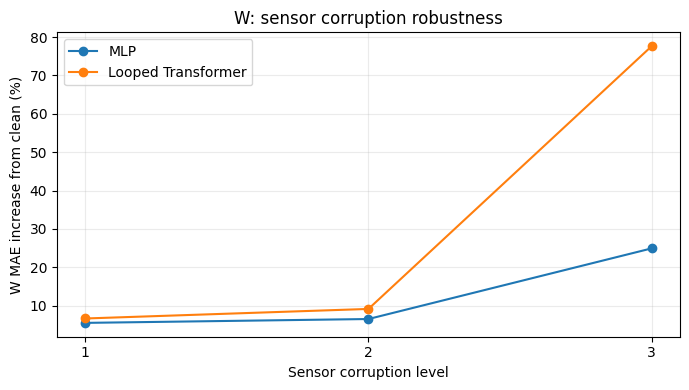

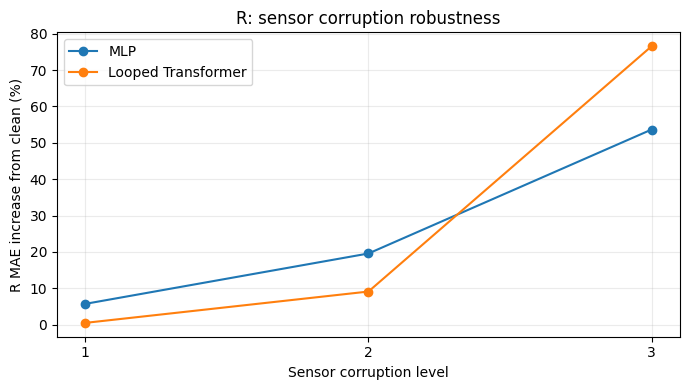

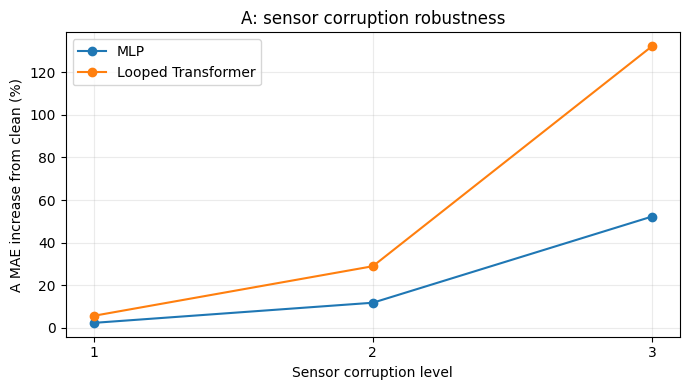

In [45]:

# ============================================================
# 15. Robustness plot
# ============================================================

import matplotlib.pyplot as plt

for target in target_names:
    plt.figure(figsize=(7, 4))

    for model_name in ["MLP", "Looped Transformer"]:
        sub = degradation_df[
            (degradation_df["Target"] == target) &
            (degradation_df["model"] == model_name)
        ].sort_values("corruption_level")

        plt.plot(
            sub["corruption_level"],
            sub["MAE_increase_%"],
            marker="o",
            label=model_name,
        )

    plt.xlabel("Sensor corruption level")
    plt.ylabel(f"{target} MAE increase from clean (%)")
    plt.title(f"{target}: sensor corruption robustness")
    plt.xticks([1, 2, 3])
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.show()
